# Step 2.1: Load & Inspect Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(df.shape)
df.info()

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

In [2]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [3]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [4]:
# Convert TotalCharges to float and impute missing values
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# Check class balance
df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


# Step 2.2: Univariate Analysis

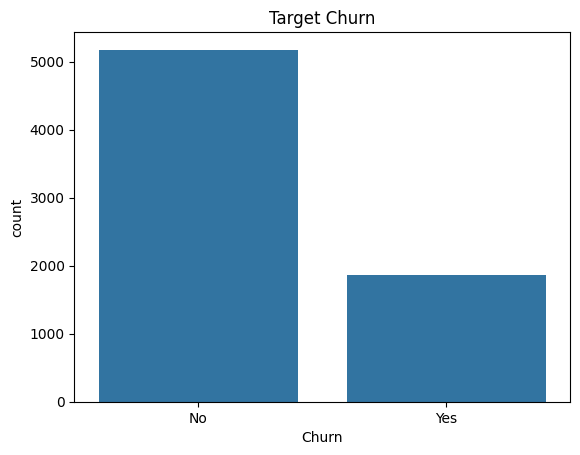

In [5]:
sns.countplot(x='Churn', data=df)
plt.title('Target Churn')
plt.show()

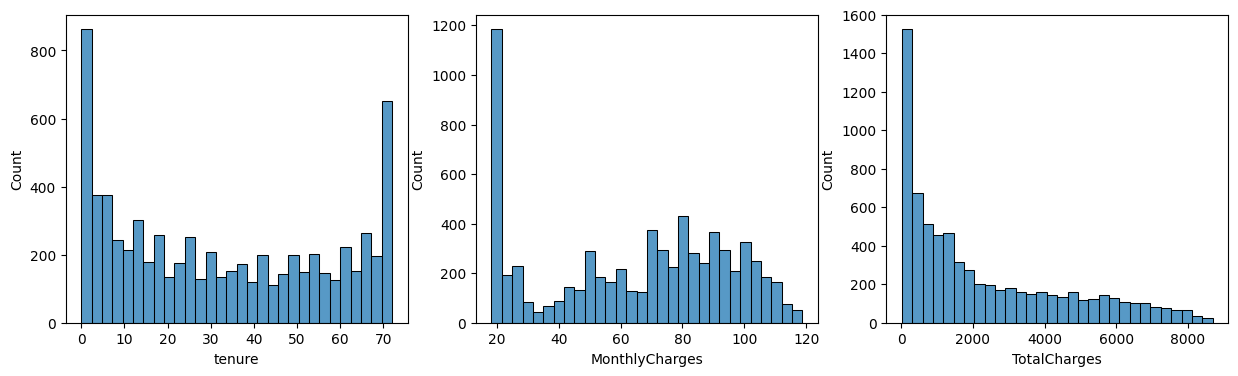

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['tenure'], bins=30, ax=axes[0])
sns.histplot(df['MonthlyCharges'], bins=30, ax=axes[1])
sns.histplot(df['TotalCharges'], bins=30, ax=axes[2])
plt.show()

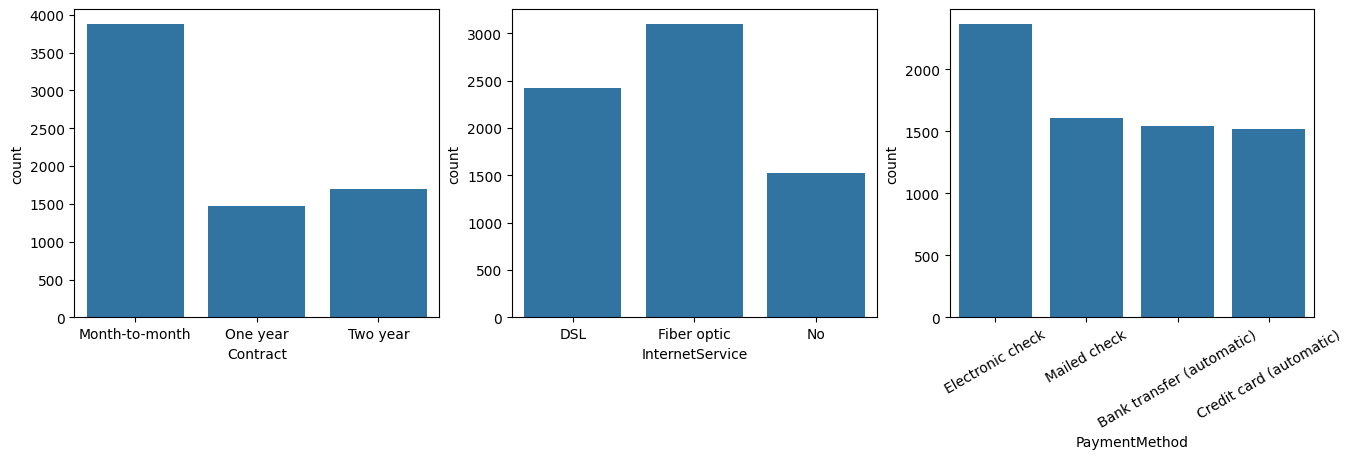

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x='Contract', data=df, ax=axes[0])
sns.countplot(x='InternetService', data=df, ax=axes[1])
sns.countplot(x='PaymentMethod', data=df, ax=axes[2])
axes[2].tick_params(axis='x', rotation=30)
plt.show()

# Step 2.3: Bivariate Analysis

,Churn
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


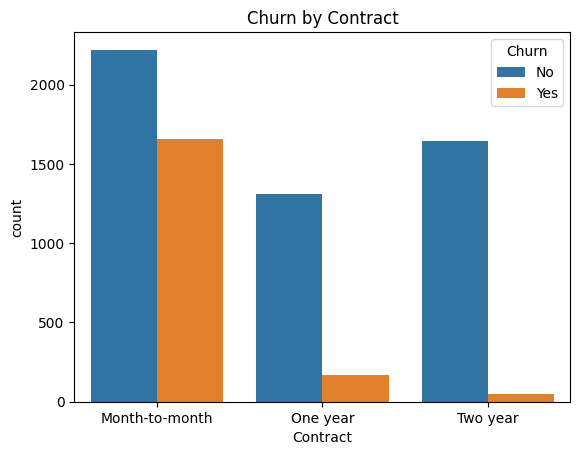

In [8]:
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn by Contract')
plt.show()

df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)

,tenure,Churn
0,0-12,47.438243
1,13-24,28.710938
2,25-48,20.388959
3,49-72,9.513176


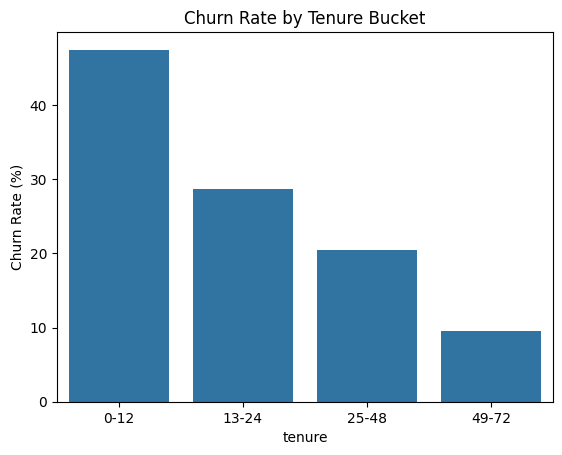

In [9]:
tenure_bins = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72], labels=['0-12', '13-24', '25-48', '49-72'])
tenure_churn = df.groupby(tenure_bins, observed=False)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()

sns.barplot(x='tenure', y='Churn', data=tenure_churn)
plt.title('Churn Rate by Tenure Bucket')
plt.ylabel('Churn Rate (%)')
plt.show()

tenure_churn

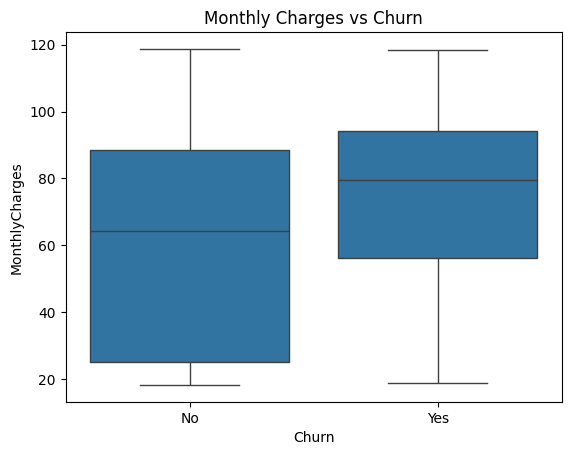

In [10]:
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title('Monthly Charges vs Churn')
plt.show()

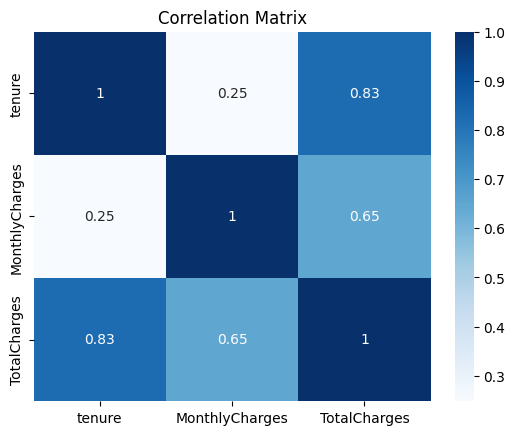

In [11]:
corr = df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr()
sns.heatmap(corr, annot=True, cmap='Blues')
plt.title('Correlation Matrix')
plt.show()

# Step 3.1: Drop customerID

In [12]:
df = df.drop(columns=['customerID'])

# Step 3.2: Feature Engineering

In [13]:
# tenure_group
df['tenure_group'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 36, 60, np.inf],
    labels=['New', 'Mid', 'Senior', 'Loyal']
)

# num_services
services = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['num_services'] = (df[services] == 'Yes').sum(axis=1)

# AutoPay
df['AutoPay'] = df['PaymentMethod'].apply(lambda x: 1 if 'automatic' in str(x).lower() else 0)

df[['tenure', 'tenure_group', 'num_services', 'AutoPay']].head()

,tenure,tenure_group,num_services,AutoPay
0,1,New,1,0
1,34,Mid,2,0
2,2,New,2,0
3,45,Senior,3,1
4,2,New,0,0


# Step 3.3: Categorical Encoding

In [14]:
# Map binary features
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

df['gender'] = df['gender'].map({'Female': 0, 'Male': 1})
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No').map({'Yes': 1, 'No': 0})

# Label encode tenure_group
tenure_order = {'New': 0, 'Mid': 1, 'Senior': 2, 'Loyal': 3}
df['tenure_group'] = df['tenure_group'].map(tenure_order).astype(int)

# Drop original service columns
df = df.drop(columns=services)

# One-hot encoding
df = pd.get_dummies(df, columns=['InternetService', 'Contract', 'PaymentMethod'], drop_first=True, dtype=int)
print(df.shape)

(7043, 21)


# Step 3.4: Train-Test Split

In [15]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)

(5634, 20) (1409, 20)


# Step 3.5: Feature Scaling

In [16]:
from sklearn.preprocessing import StandardScaler

scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'num_services']
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

# Step 3.6: Handle Class Imbalance with SMOTE

In [17]:
from imblearn.over_sampling import SMOTE

print("Before SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("After SMOTE:")
print(pd.Series(y_train_smote).value_counts())

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64
After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


# Step 4.1: K-Nearest Neighbours (KNN)

In [18]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

knn5 = KNeighborsClassifier(n_neighbors=5)
knn5.fit(X_train_smote, y_train_smote)
y_pred_knn5 = knn5.predict(X_test_scaled)
y_prob_knn5 = knn5.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred_knn5), 4))
print("Precision:", round(precision_score(y_test, y_pred_knn5), 4))
print("Recall:", round(recall_score(y_test, y_pred_knn5), 4))
print("F1:", round(f1_score(y_test, y_pred_knn5), 4))
print("AUC:", round(roc_auc_score(y_test, y_prob_knn5), 4))

Accuracy: 0.7111
Precision: 0.4707
Recall: 0.7086
F1: 0.5656
AUC: 0.7744


Best k: 15


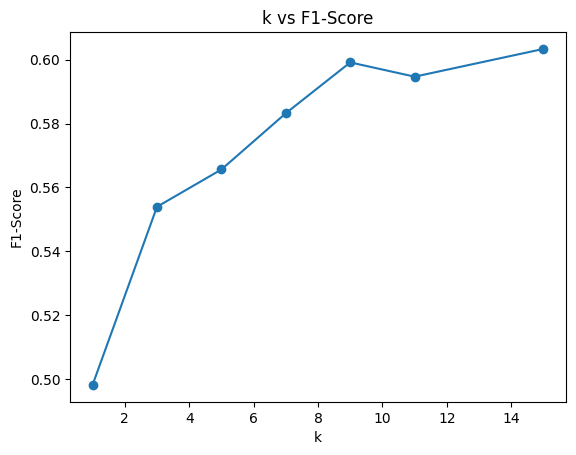

In [19]:
k_values = [1, 3, 5, 7, 9, 11, 15]
f1_scores = []

for k in k_values:
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train_smote, y_train_smote)
    pred = clf.predict(X_test_scaled)
    f1_scores.append(f1_score(y_test, pred))

plt.plot(k_values, f1_scores, marker='o')
plt.xlabel('k')
plt.ylabel('F1-Score')
plt.title('k vs F1-Score')
plt.show()

best_k = k_values[np.argmax(f1_scores)]
print("Best k:", best_k)

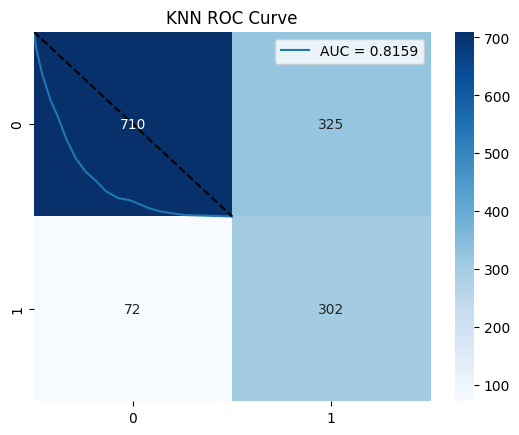

In [20]:
import time
t0 = time.time()
knn_opt = KNeighborsClassifier(n_neighbors=best_k)
knn_opt.fit(X_train_smote, y_train_smote)
time_knn = time.time() - t0

y_pred_knn = knn_opt.predict(X_test_scaled)
y_prob_knn = knn_opt.predict_proba(X_test_scaled)[:, 1]

sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Blues')
plt.title(f'KNN (k={best_k}) Confusion Matrix')
plt.show()

fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
auc_knn = roc_auc_score(y_test, y_prob_knn)
plt.plot(fpr_knn, tpr_knn, label=f'AUC = {auc_knn:.4f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('KNN ROC Curve')
plt.legend()
plt.show()

# Step 4.2: Gaussian Naive Bayes

Accuracy: 0.7239
Precision: 0.4876
Recall: 0.7914
F1: 0.6035
AUC: 0.8165
class_prior_: [0.5 0.5]


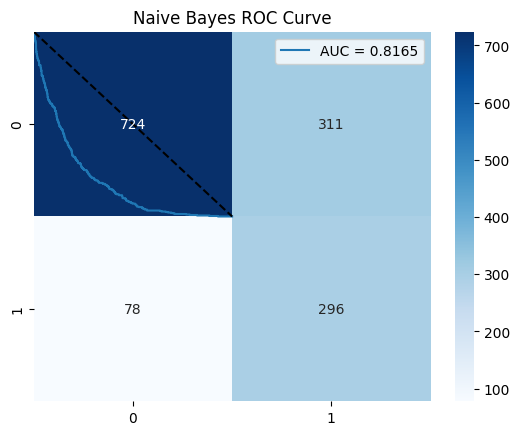

In [21]:
from sklearn.naive_bayes import GaussianNB

t0 = time.time()
gnb = GaussianNB()
gnb.fit(X_train_smote, y_train_smote)
time_gnb = time.time() - t0

y_pred_gnb = gnb.predict(X_test_scaled)
y_prob_gnb = gnb.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred_gnb), 4))
print("Precision:", round(precision_score(y_test, y_pred_gnb), 4))
print("Recall:", round(recall_score(y_test, y_pred_gnb), 4))
print("F1:", round(f1_score(y_test, y_pred_gnb), 4))
print("AUC:", round(roc_auc_score(y_test, y_prob_gnb), 4))
print("class_prior_:", gnb.class_prior_)

sns.heatmap(confusion_matrix(y_test, y_pred_gnb), annot=True, fmt='d', cmap='Blues')
plt.title('Naive Bayes Confusion Matrix')
plt.show()

fpr_gnb, tpr_gnb, _ = roc_curve(y_test, y_prob_gnb)
auc_gnb = roc_auc_score(y_test, y_prob_gnb)
plt.plot(fpr_gnb, tpr_gnb, label=f'AUC = {auc_gnb:.4f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Naive Bayes ROC Curve')
plt.legend()
plt.show()

# Step 5.1: Support Vector Machine (SVM)

Accuracy: 0.7445
Precision: 0.5125
Recall: 0.7701
F1: 0.6154
AUC: 0.8222


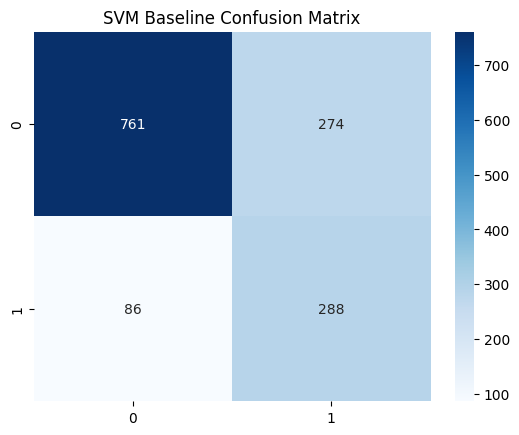

In [22]:
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

svm_base = SVC(kernel='rbf', C=1, gamma='scale', probability=True, random_state=42)
svm_base.fit(X_train_smote, y_train_smote)
y_pred_svm_base = svm_base.predict(X_test_scaled)
y_prob_svm_base = svm_base.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred_svm_base), 4))
print("Precision:", round(precision_score(y_test, y_pred_svm_base), 4))
print("Recall:", round(recall_score(y_test, y_pred_svm_base), 4))
print("F1:", round(f1_score(y_test, y_pred_svm_base), 4))
print("AUC:", round(roc_auc_score(y_test, y_prob_svm_base), 4))

sns.heatmap(confusion_matrix(y_test, y_pred_svm_base), annot=True, fmt='d', cmap='Blues')
plt.title('SVM Baseline Confusion Matrix')
plt.show()

Best C: 100


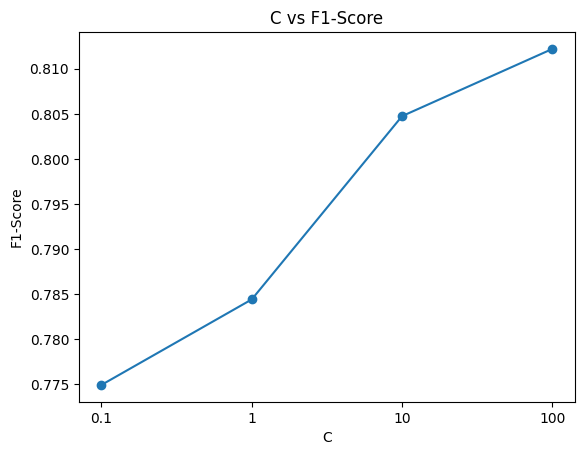

In [23]:
c_list = [0.1, 1, 10, 100]
c_scores = []

for c in c_list:
    clf = SVC(kernel='rbf', C=c, gamma='scale', probability=False, random_state=42)
    score = cross_val_score(clf, X_train_smote, y_train_smote, cv=3, scoring='f1').mean()
    c_scores.append(score)

plt.plot([str(c) for c in c_list], c_scores, marker='o')
plt.xlabel('C')
plt.ylabel('F1-Score')
plt.title('C vs F1-Score')
plt.show()

best_c = c_list[np.argmax(c_scores)]
print("Best C:", best_c)

Accuracy: 0.7275
Precision: 0.4908
Recall: 0.7139
F1: 0.5817
AUC: 0.7886


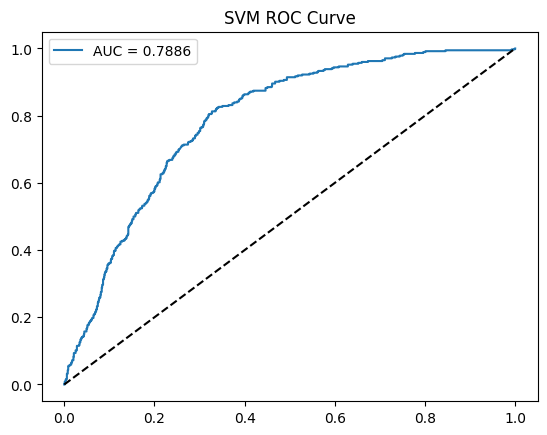

In [24]:
t0 = time.time()
svm_opt = SVC(kernel='rbf', C=best_c, gamma='scale', probability=True, random_state=42)
svm_opt.fit(X_train_smote, y_train_smote)
time_svm = time.time() - t0

y_pred_svm = svm_opt.predict(X_test_scaled)
y_prob_svm = svm_opt.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred_svm), 4))
print("Precision:", round(precision_score(y_test, y_pred_svm), 4))
print("Recall:", round(recall_score(y_test, y_pred_svm), 4))
print("F1:", round(f1_score(y_test, y_pred_svm), 4))
print("AUC:", round(roc_auc_score(y_test, y_prob_svm), 4))

fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
auc_svm = roc_auc_score(y_test, y_prob_svm)
plt.plot(fpr_svm, tpr_svm, label=f'AUC = {auc_svm:.4f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('SVM ROC Curve')
plt.legend()
plt.show()

# Step 5.2: Decision Tree Classifier

Accuracy: 0.7488
Precision: 0.5178
Recall: 0.7781
F1: 0.6218
AUC: 0.8287
Root split feature: Contract_Two year


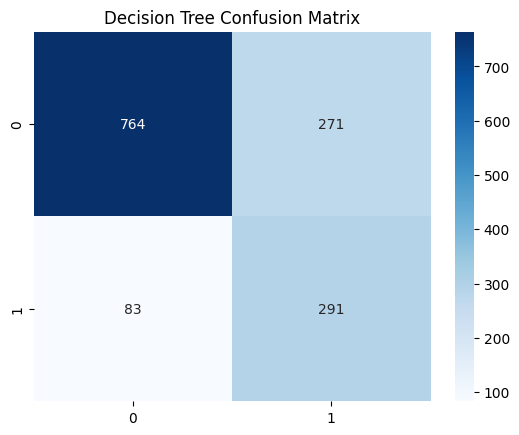

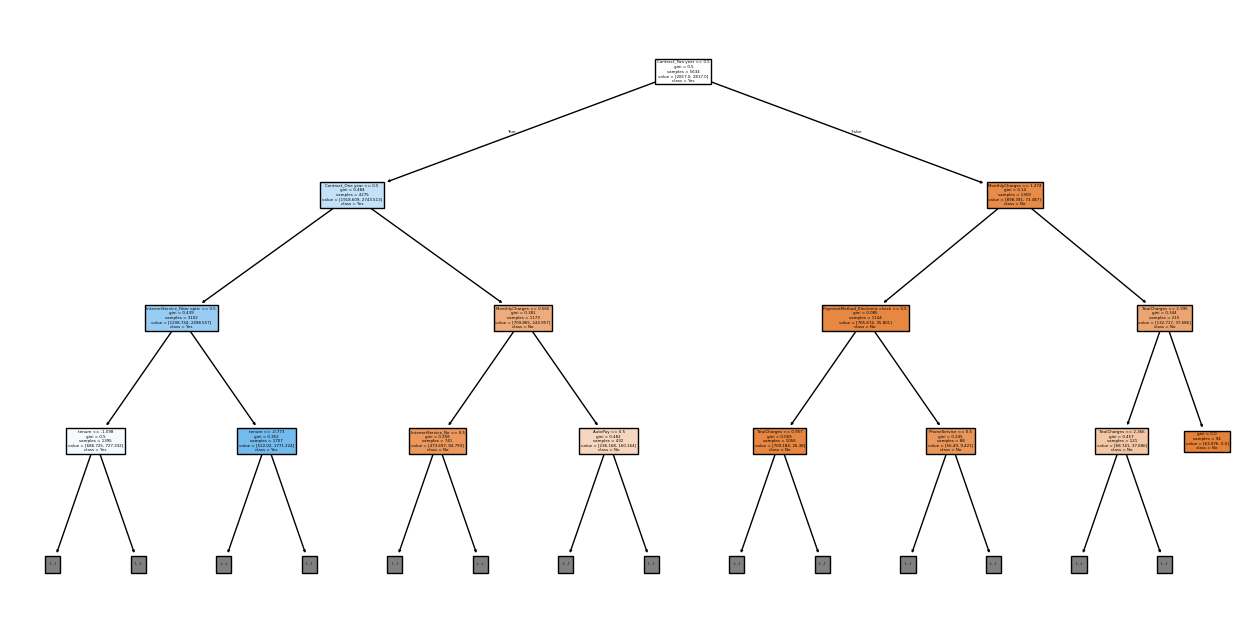

In [25]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt_base = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
dt_base.fit(X_train_scaled, y_train)
y_pred_dt_base = dt_base.predict(X_test_scaled)
y_prob_dt_base = dt_base.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred_dt_base), 4))
print("Precision:", round(precision_score(y_test, y_pred_dt_base), 4))
print("Recall:", round(recall_score(y_test, y_pred_dt_base), 4))
print("F1:", round(f1_score(y_test, y_pred_dt_base), 4))
print("AUC:", round(roc_auc_score(y_test, y_prob_dt_base), 4))

sns.heatmap(confusion_matrix(y_test, y_pred_dt_base), annot=True, fmt='d', cmap='Blues')
plt.title('Decision Tree Confusion Matrix')
plt.show()

plt.figure(figsize=(16, 8))
plot_tree(
    dt_base,
    max_depth=3,
    feature_names=X.columns,
    class_names=['No', 'Yes'],
    filled=True
)
plt.show()

print("Root split feature:", X.columns[dt_base.tree_.feature[0]])

Best depth: 7


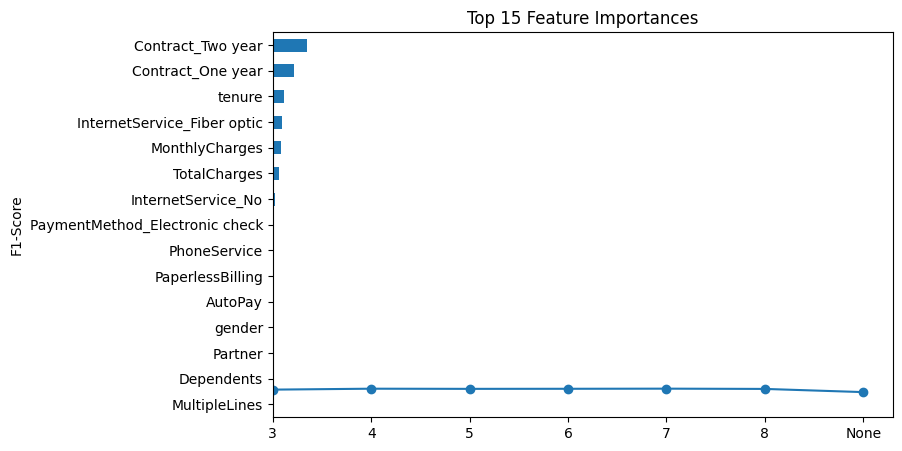

In [26]:
depth_list = [3, 4, 5, 6, 7, 8, None]
depth_scores = []

for d in depth_list:
    clf = DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=42)
    score = cross_val_score(clf, X_train_scaled, y_train, cv=5, scoring='f1').mean()
    depth_scores.append(score)

plt.plot([str(d) for d in depth_list], depth_scores, marker='o')
plt.xlabel('max_depth')
plt.ylabel('F1-Score')
plt.title('max_depth vs F1-Score')
plt.show()

best_depth = depth_list[np.argmax(depth_scores)]
print("Best depth:", best_depth)

t0 = time.time()
dt_opt = DecisionTreeClassifier(max_depth=best_depth, class_weight='balanced', random_state=42)
dt_opt.fit(X_train_scaled, y_train)
time_dt = time.time() - t0

y_pred_dt = dt_opt.predict(X_test_scaled)
y_prob_dt = dt_opt.predict_proba(X_test_scaled)[:, 1]

importances = pd.Series(dt_opt.feature_importances_, index=X.columns).sort_values()
importances.tail(15).plot(kind='barh', figsize=(8, 5))
plt.title('Top 15 Feature Importances')
plt.show()

# Step 5.3: class_weight='balanced' vs SMOTE

In [27]:
dt_smote = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = dt_smote.predict(X_test_scaled)

dt_cw = DecisionTreeClassifier(max_depth=best_depth, class_weight='balanced', random_state=42)
dt_cw.fit(X_train_scaled, y_train)
y_pred_cw = dt_cw.predict(X_test_scaled)

print("Recall (SMOTE):", round(recall_score(y_test, y_pred_smote), 4))
print("Recall (class_weight='balanced'):", round(recall_score(y_test, y_pred_cw), 4))

Recall (SMOTE): 0.7834
Recall (class_weight='balanced'): 0.762


# Step 6: Model Evaluation & Comparison

In [28]:
comparison_table = pd.DataFrame([
    {
        'Model': f'KNN (k={best_k})',
        'Accuracy': round(accuracy_score(y_test, y_pred_knn), 4),
        'Precision': round(precision_score(y_test, y_pred_knn), 4),
        'Recall': round(recall_score(y_test, y_pred_knn), 4),
        'F1-Score': round(f1_score(y_test, y_pred_knn), 4),
        'AUC-ROC': round(auc_knn, 4),
        'Training Time (s)': round(time_knn, 4)
    },
    {
        'Model': 'Gaussian NB',
        'Accuracy': round(accuracy_score(y_test, y_pred_gnb), 4),
        'Precision': round(precision_score(y_test, y_pred_gnb), 4),
        'Recall': round(recall_score(y_test, y_pred_gnb), 4),
        'F1-Score': round(f1_score(y_test, y_pred_gnb), 4),
        'AUC-ROC': round(auc_gnb, 4),
        'Training Time (s)': round(time_gnb, 4)
    },
    {
        'Model': f'SVM (C={best_c})',
        'Accuracy': round(accuracy_score(y_test, y_pred_svm), 4),
        'Precision': round(precision_score(y_test, y_pred_svm), 4),
        'Recall': round(recall_score(y_test, y_pred_svm), 4),
        'F1-Score': round(f1_score(y_test, y_pred_svm), 4),
        'AUC-ROC': round(auc_svm, 4),
        'Training Time (s)': round(time_svm, 4)
    },
    {
        'Model': f'Decision Tree (depth={best_depth})',
        'Accuracy': round(accuracy_score(y_test, y_pred_dt), 4),
        'Precision': round(precision_score(y_test, y_pred_dt), 4),
        'Recall': round(recall_score(y_test, y_pred_dt), 4),
        'F1-Score': round(f1_score(y_test, y_pred_dt), 4),
        'AUC-ROC': round(roc_auc_score(y_test, y_prob_dt), 4),
        'Training Time (s)': round(time_dt, 4)
    }
])

comparison_table = comparison_table.sort_values(by='Recall', ascending=False).reset_index(drop=True)
comparison_table

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Training Time (s)
0,KNN (k=15),0.7182,0.4817,0.8075,0.6034,0.8159,0.0130
1,Gaussian NB,0.7239,0.4876,0.7914,0.6035,0.8165,0.0097
2,Decision Tree (depth=7),0.7537,0.5249,0.7620,0.6216,0.8267,0.0280
3,SVM (C=100),0.7275,0.4908,0.7139,0.5817,0.7886,45.5756


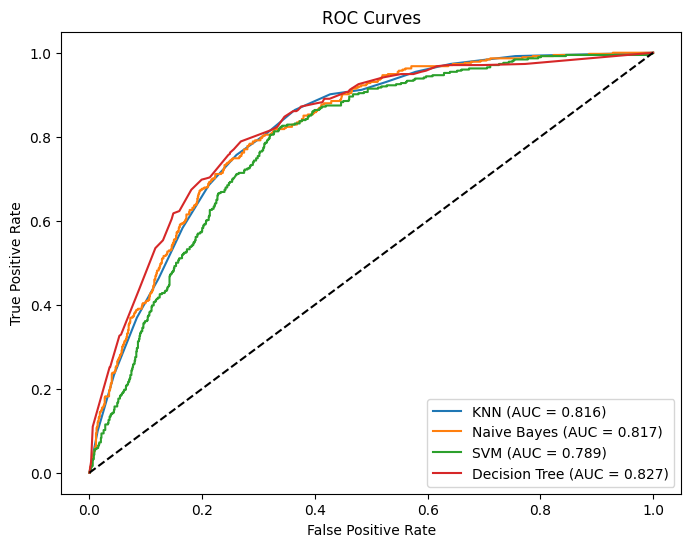

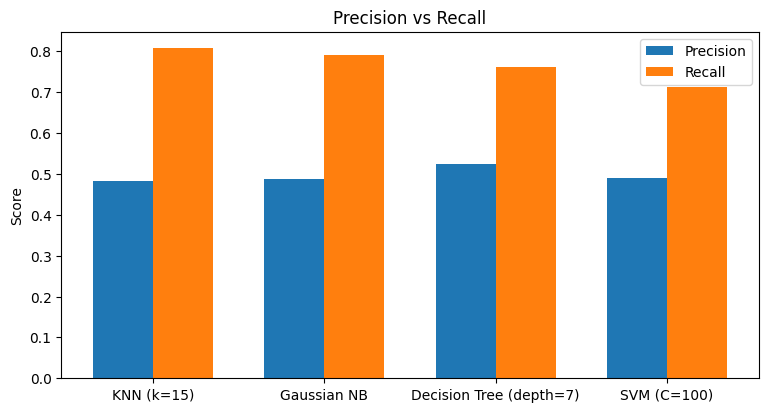

In [29]:
# Plot all 4 ROC curves
plt.figure(figsize=(8, 6))
plt.plot(fpr_knn, tpr_knn, label=f'KNN (AUC = {auc_knn:.3f})')
plt.plot(fpr_gnb, tpr_gnb, label=f'Naive Bayes (AUC = {auc_gnb:.3f})')
plt.plot(fpr_svm, tpr_svm, label=f'SVM (AUC = {auc_svm:.3f})')
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {roc_auc_score(y_test, y_prob_dt):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.show()

# Precision vs Recall bar chart
x = np.arange(len(comparison_table))
width = 0.35

plt.figure(figsize=(9, 4.5))
plt.bar(x - width/2, comparison_table['Precision'], width, label='Precision')
plt.bar(x + width/2, comparison_table['Recall'], width, label='Recall')
plt.xticks(x, comparison_table['Model'])
plt.ylabel('Score')
plt.title('Precision vs Recall')
plt.legend()
plt.show()

# Step 7.1: Error Analysis on Best Model

In [30]:
audit = X_test.copy()
audit['Actual'] = y_test
audit['Predicted'] = y_pred_dt

fn = audit[(audit['Actual'] == 1) & (audit['Predicted'] == 0)]
all_churners = audit[audit['Actual'] == 1]

fn_profile = pd.DataFrame({
    'Metric': [
        'Average Tenure',
        'Average MonthlyCharges',
        'One-Year Contract (%)',
        'Two-Year Contract (%)'
    ],
    'False Negatives': [
        round(fn['tenure'].mean(), 2),
        round(fn['MonthlyCharges'].mean(), 2),
        round(fn['Contract_One year'].mean() * 100, 2),
        round(fn['Contract_Two year'].mean() * 100, 2)
    ],
    'All Churners': [
        round(all_churners['tenure'].mean(), 2),
        round(all_churners['MonthlyCharges'].mean(), 2),
        round(all_churners['Contract_One year'].mean() * 100, 2),
        round(all_churners['Contract_Two year'].mean() * 100, 2)
    ]
})

fn_profile

,Metric,False Negatives,All Churners
0,Average Tenure,31.49,16.46
1,Average MonthlyCharges,64.89,72.77
2,One-Year Contract (%),39.33,9.63
3,Two-Year Contract (%),8.99,2.41


# Step 7.2: Decision Tree Feature Importance

In [31]:
top_5 = importances.tail(5).sort_values(ascending=False)
for feat, imp in top_5.items():
    print(f"{feat}: {imp:.4f}")

Contract_Two year: 0.3472
Contract_One year: 0.2172
tenure: 0.1139
InternetService_Fiber optic: 0.0956
MonthlyCharges: 0.0788


# Step 8.1: Save Final Pipeline & Predict

In [32]:
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

scale_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'num_services']

preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), scale_features)
    ],
    remainder='passthrough'
)

final_model = DecisionTreeClassifier(max_depth=best_depth, class_weight='balanced', random_state=42)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', final_model)
])

pipeline.fit(X_train, y_train)
joblib.dump(pipeline, 'churn_model.pkl')

sample_customers = X_test.head(5)
probs = pipeline.predict_proba(sample_customers)[:, 1]
labels = pipeline.predict(sample_customers)

for i in range(5):
    print(f"Customer {i+1}: Prob={probs[i]:.4f}, Label={labels[i]}")

Customer 1: Prob=0.0000, Label=0
Customer 2: Prob=0.8795, Label=1
Customer 3: Prob=0.1627, Label=0
Customer 4: Prob=0.6558, Label=1
Customer 5: Prob=0.0000, Label=0
